# MyFinSight 분석 결과 한눈에 보기

`output/13_results.json` 하나만 읽어서, 파이프라인이 **무엇을 받아(요청) → 어떻게 이해하고(의도) → 어떤 종목을 골라(선정) → 어떻게 나누고(구성) → 과거에 적용하면 어땠고(백테스트) → 기준을 통과했는지(검증)** 를 순서대로 보여줍니다.
각 절의 표와 그래프는 모두 같은 결과 파일의 숫자입니다.

In [1]:
import json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams["font.family"] = "AppleGothic"      # macOS 한글 폰트 (다른 OS: 'Malgun Gothic' / 'NanumGothic')
mpl.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 160)

import os
RESULTS = Path(os.environ.get("MYFINSIGHT_RESULTS", "../output/13_results.json"))   # 기본: notebooks/ 기준 상대 경로
R = json.loads(RESULTS.read_text(encoding="utf-8"))
pct = lambda x: "–" if x is None else f"{x*100:+.2f}%"
pct1 = lambda x: "–" if x is None else f"{x*100:.1f}%"
usd = lambda x: "–" if x is None else f"{x:,.2f} USD"
krw = lambda x: "–" if x is None else f"{x:,.0f}원"
print("request_id:", R["request_id"], "| generated:", R["generated_at"], "| pipeline:", R["pipeline_version"])

request_id: req_2026-10-10_ai2 | generated: 2026-10-10T12:00:50 | pipeline: mockup-2026.10


## 1. 요청 — 사용자가 입력한 것

In [2]:
q, d, c, h, r = R["request"], R["request"]["derived"], R["request"]["capital"], R["request"]["horizon"], R["request"]["risk"]
rows = [("투자금", f"{c['initial_amount']:,.0f}원 → {usd(d['initial_amount_usd'])}  (환율 {R['money_krw']['direction']}, {d['fx_date']})"),
        ("월 적립", f"{c['monthly_contribution']:,.0f}원 (매월 {c['contribution_day']}일) → {usd(d['monthly_contribution_usd'])}"),
        ("투자기간", f"{h['target_years']}년, 시작 희망일 {h['start_date']}"),
        ("투자성향", f"{r['risk_tolerance']} · 손실 감내 수준 {r['max_drawdown_tolerance']:.0%} · 손실 시 {r['loss_reaction']}"),
        ("목표 수익률 / 비교지수", f"연 {r['target_annual_return']:.0%} / {r['benchmark']}"),
        ("전략 템플릿 / 기준 비중", f"{q['strategy_preference']['template']} / {q['strategy_preference']['baseline_weighting']}"),
        ("투자 아이디어", q["natural_language"]["idea"])]
pd.DataFrame(rows, columns=["항목", "내용"]).set_index("항목")

,내용
항목,
투자금,"10,000,000원 → 7,462.58 USD (환율 1 USD = 1,340.02 KRW, 2026-10-09)"
월 적립,"500,000원 (매월 25일) → 373.13 USD"
투자기간,"3.0년, 시작 희망일 2026-10-09"
투자성향,moderate · 손실 감내 수준 25% · 손실 시 hold
목표 수익률 / 비교지수,연 12% / SPY
전략 템플릿 / 기준 비중,momentum / equal_weight
투자 아이디어,AI 반도체와 클라우드 인프라 관련 기업 중 최근 1년간 주가 흐름이 강한 종목 위주로 3년 정도 들고 가고 싶어요. 변동성은 어느 정도...


## 2. 의도 해석 — 분석 모델이 아이디어를 어떻게 이해했나

In [3]:
I = R["intent"]
print(I["interpretation"]["summary_ko"]); print()
themes = pd.DataFrame([{"테마": t["label_ko"], "설명": t["description_ko"], "GICS 코드": ", ".join(t["gics_codes"]), "키워드": ", ".join(t["keywords"][:6])} for t in I["interpretation"]["themes"]])
display(themes.set_index("테마"))
cons = q["constraints"]
display(pd.DataFrame([("종목 수", f"목표 {cons['num_holdings']['target']} (허용 {cons['num_holdings']['min']}~{cons['num_holdings']['max']})"), ("종목당 상한", f"{cons['max_weight_per_stock']:.0%}"), ("섹터당 상한", f"{cons['max_weight_per_sector']:.0%}"),
                      ("리밸런싱", d["rebalance_rule"]["description_ko"]), ("제외 테마", ", ".join(cons["exclude_themes"]) or "없음"),
                      ("변동성 선호 / 허용 MDD", f"{I['risk_params']['volatility_preference']} / {I['risk_params']['effective_max_drawdown']:.0%}"), ("해석 메모", I["risk_params"]["notes_ko"])], columns=["항목", "값"]).set_index("항목"))
if I["interpretation"]["conflicts"]:
    display(pd.DataFrame(I["interpretation"]["conflicts"]).rename(columns={"field": "항목", "issue_ko": "확인한 점", "resolution_ko": "처리"}))

AI 반도체와 클라우드 인프라 기업 중 최근 12개월 주가 흐름이 강한 종목을 중심으로 3년간 투자하려는 요청입니다. 변동성을 어느 정도 감수하되 종목별 쏠림은 피하는 방향으로 해석했습니다.



,설명,GICS 코드,키워드
테마,,,
AI 반도체,"AI 학습·추론용 GPU, 가속기, 메모리 및 관련 반도체 설계·제조·장비 기업을 포함합니다. AI 반도체 공급망에서 의미 있는 사업을 ...","453010, 45203015","gpu, ai accelerator, data center gpu, artificial intelligence chip, semicond..."
클라우드 인프라,"클라우드 컴퓨팅 플랫폼과 이를 뒷받침하는 시스템 소프트웨어, 서버·저장장치, 네트워크 장비, 데이터센터 및 데이터센터 전력 인프라 기업을...","45102030, 45103020, 45202030, 45201020, 60108050, 20104010","cloud computing, cloud platform, hyperscale cloud, data center, colocation, ..."


,값
항목,
종목 수,목표 15 (허용 10~20)
종목당 상한,15%
섹터당 상한,40%
리밸런싱,1×분기마다 리밸런싱
제외 테마,"tobacco, gambling"
변동성 선호 / 허용 MDD,medium / 25%
해석 메모,큰 손실 시 보유(hold)를 예상하므로 최대 낙폭 허용치는 조정하지 않았습니다. 투자 경험이 beginner이지만 none은 아니므로 ...


## 3. 종목 선정 — 깔때기와 선정 표

유니버스 → 테마 관련 후보(GICS·키워드) → 테마 해당 판정(분석 모델) → 선정 지표 순위 → 섹터 상한 → 최종. 백테스트는 시작일 당시 정보로 같은 규칙을 다시 적용하므로 목록이 다를 수 있습니다.

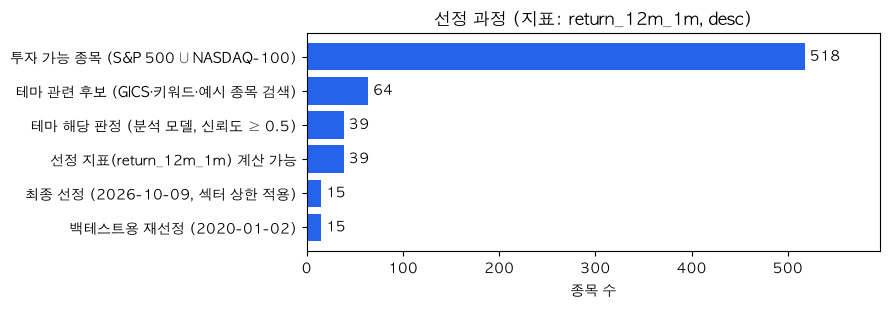

,회사,섹터,테마,신뢰도,순위(2020-01-02),지표(백테스트),순위(2026-10-09),지표(2026),테마 판정 사유
티커,,,,,,,,,
AMD,Advanced Micro Devices,Information Technology,ai_semiconductors,0.90,1.0,+105.68%,NaN,+nan%,"데이터센터용 GPU와 AI 가속기, 서버 CPU를 공급"
TER,Teradyne,Information Technology,ai_semiconductors,0.50,2.0,+98.50%,14.0,+156.51%,반도체 테스트 장비를 공급해 AI 칩 제조·검증 공급망에 참여
LRCX,Lam Research,Information Technology,ai_semiconductors,0.65,3.0,+93.32%,NaN,+nan%,AI 반도체 제조에 필요한 웨이퍼 식각·증착 장비를 공급
KLAC,KLA Corporation,Information Technology,ai_semiconductors,0.65,4.0,+81.45%,NaN,+nan%,첨단 AI 칩 제조에 쓰이는 반도체 공정 제어·검사 장비 공급
AMAT,Applied Materials,Information Technology,ai_semiconductors,0.55,5.0,+72.45%,NaN,+nan%,AI 칩 생산에 필요한 웨이퍼 공정·검사 장비를 공급
ASML,ASML Holding,Information Technology,ai_semiconductors,0.70,6.0,+72.21%,NaN,+nan%,첨단 AI 반도체 제조에 필수적인 노광 장비를 공급
EQIX,Equinix,Real Estate,cloud_infrastructure,0.95,7.0,+60.20%,10.0,+30.13%,기업과 클라우드 사업자를 위한 데이터센터·상호접속 시설 운영
ETN,Eaton Corporation,Industrials,cloud_infrastructure,0.50,8.0,+38.74%,12.0,+9.52%,데이터센터 전력 공급·관리용 전기 장비를 제공
GOOGL,Alphabet Inc. (Class A),Communication Services,"ai_semiconductors, cloud_infrastructure",0.55,9.0,+22.21%,9.0,+36.32%,Google Cloud를 운영하고 자체 TPU를 설계·활용


백테스트 재선정에서 추가: ['AMAT', 'AMD', 'ASML', 'KLAC', 'LRCX', 'MRVL', 'MSFT', 'NVDA'] | 빠짐: ['BE', 'COHR', 'DELL', 'INTC', 'LITE', 'MU', 'VRT', 'WDC']


,회사,제외 이유,지표값
티커,,,
MRVL,Marvell Technology,rank_beyond_n,1.458672
HPE,Hewlett Packard Enterprise,rank_beyond_n,1.149883
AMD,Advanced Micro Devices,rank_beyond_n,1.137884
AMAT,Applied Materials,rank_beyond_n,1.098886
LRCX,Lam Research,rank_beyond_n,1.098182
GLW,Corning Inc.,rank_beyond_n,0.889713
NBIS,Nebius Group,rank_beyond_n,0.869754
ASML,ASML Holding,rank_beyond_n,0.717818


In [4]:
S = R["selection"]
f = pd.DataFrame(S["funnel"])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(f["label_ko"][::-1], f["count"][::-1], color="#2563eb")
for i, v in enumerate(f["count"][::-1]): ax.text(v + 5, i, str(v), va="center")
ax.set_xlabel("종목 수"); ax.set_title(f"선정 과정 (지표: {S['metric']}, {S['direction']})"); ax.set_xlim(0, f["count"].max() * 1.15)
plt.tight_layout(); plt.show()

t = pd.DataFrame(S["table"])
view = t[["ticker", "name", "sector", "themes", "theme_confidence", "rank_backtest", "metric_backtest", "rank_2026", "metric_2026", "theme_reason_ko"]].copy()
view["themes"] = view["themes"].str.join(", "); view["metric_backtest"] = view["metric_backtest"].map(pct); view["metric_2026"] = view["metric_2026"].map(pct)
view.columns = ["티커", "회사", "섹터", "테마", "신뢰도", f"순위({S['backtest_as_of']['as_of']})", "지표(백테스트)", f"순위({S['as_of_2026']['as_of']})", "지표(2026)", "테마 판정 사유"]
display(view.set_index("티커"))
diff = S["backtest_as_of"]["diff_vs_original"]
print("백테스트 재선정에서 추가:", diff["added"], "| 빠짐:", diff["removed"])
display(pd.DataFrame(S["as_of_2026"]["rejected_examples"]).rename(columns={"ticker": "티커", "name": "회사", "reason": "제외 이유", "metric_value": "지표값"}).set_index("티커"))

## 4. 포트폴리오 구성 — 기준 비중, 규칙 4가지, 시나리오 5개

기준은 1/N 동일비중이고, 종목·섹터 상한으로 재배분합니다. Black-Litterman 타겟은 기준 비중에 시나리오 뷰를 종목당 최대 `max_tilt` 만큼만 반영한 것입니다.

,섹터,1/N,최종 비중
AMD,Information Technology,6.7%,4.0%
TER,Information Technology,6.7%,4.0%
LRCX,Information Technology,6.7%,4.0%
KLAC,Information Technology,6.7%,4.0%
AMAT,Information Technology,6.7%,4.0%
ASML,Information Technology,6.7%,4.0%
EQIX,Real Estate,6.7%,12.0%
ETN,Industrials,6.7%,12.0%
GOOGL,Communication Services,6.7%,12.0%
DLR,Real Estate,6.7%,12.0%


적용된 제약: ['sector_cap:Information Technology'] | 섹터 비중: {'Information Technology': 0.4, 'Real Estate': 0.24, 'Industrials': 0.12, 'Communication Services': 0.12, 'Consumer Discretionary': 0.12}


,설명,예상 변동성,유효 종목 수,최대 비중
규칙,,,,
동일비중,모든 종목에 같은 비중 1/N,18.5%,11.4,12.0%
시가총액비중,시가총액에 비례한 비중 (지수 방식),19.0%,10.0,15.0%
역변동성비중,변동성이 낮은 종목에 더 큰 비중 (1/σ 정규화),17.9%,11.2,13.1%
최소분산,포트폴리오 분산을 최소화하는 비중 (제약 포함 최적화),16.2%,8.2,15.0%


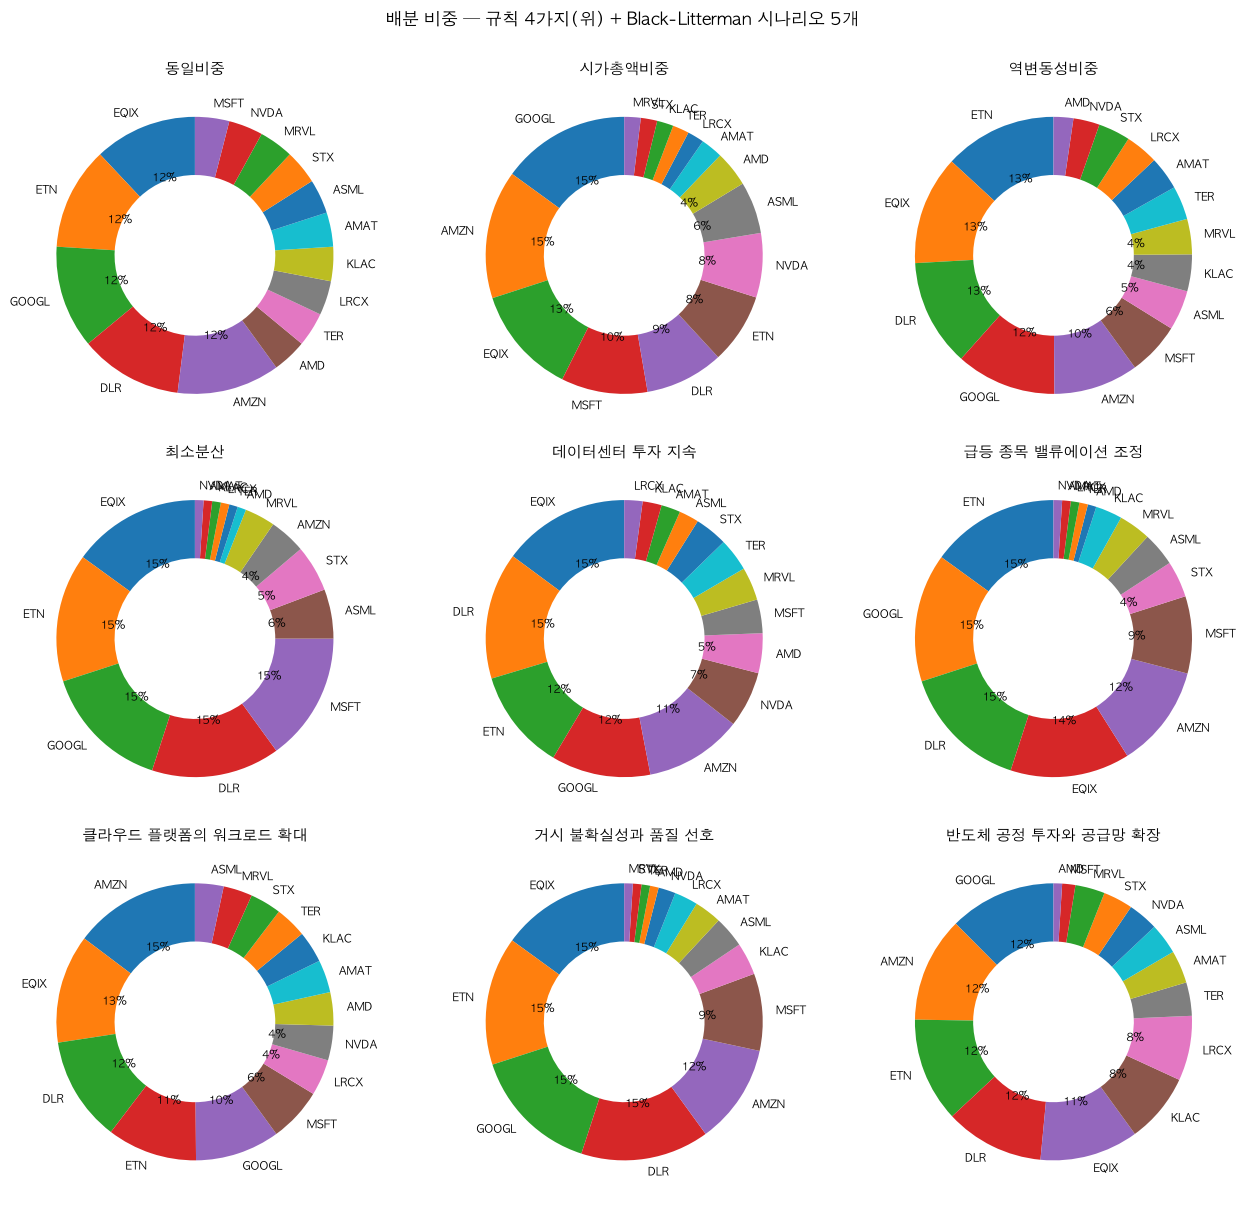

In [5]:
P = R["portfolio"]; base = next(p for p in P["baselines"]["portfolios"] if p["id"] == P["baselines"]["chosen_baseline"])
n = len(base["weights"]); sec = {x["ticker"]: x["sector"] for x in S["table"]}
bt_ = pd.DataFrame({"섹터": {t: sec.get(t, "") for t in base["weights"]}, "1/N": {t: 1/n for t in base["weights"]}, "최종 비중": base["weights"]})
display(bt_.style.format({"1/N": "{:.1%}", "최종 비중": "{:.1%}"}))
print("적용된 제약:", base["constraints_applied"], "| 섹터 비중:", {k: round(v, 3) for k, v in base["sector_weights"].items()})

tmpl = pd.DataFrame([{"규칙": p["name_ko"], "설명": p["rule_ko"], "예상 변동성": p["ex_ante"]["vol"], "유효 종목 수": p["ex_ante"]["effective_n"], "최대 비중": max(p["weights"].values())} for p in P["baselines"]["portfolios"]])
display(tmpl.set_index("규칙").style.format({"예상 변동성": "{:.1%}", "최대 비중": "{:.1%}", "유효 종목 수": "{:.1f}"}))

ports = P["baselines"]["portfolios"] + P["targets"]["portfolios"]
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, p in zip(axes.flat, ports):
    items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
    ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
    ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=11)
plt.suptitle("배분 비중 — 규칙 4가지(위) + Black-Litterman 시나리오 5개", y=1.0); plt.tight_layout(); plt.show()

,관점,뷰,최대 변화,예상 수익,예상 변동성
시나리오,,,,,
데이터센터 투자 지속,클라우드 사업자들의 데이터센터 증설과 AI 연산 수요가 반도체 투자로 이어지는 시나리오입니다. 포트폴리오에서는 가속기와 제조장비 공급망을 데이터센터 부동산보다 선호합니다.,[절대] NVDA +41%/년 (신뢰 0.38) / [상대] LRCX+KLAC > EQIX +9%/년 (신뢰 0.34) / [절대] AMD +44%/년 (신뢰 0.31) / [상대] AMAT+ASML > DLR +8%/년 (신뢰 0.32),+2.9%,20.4%,18.4%
급등 종목 밸류에이션 조정,최근 강한 주가 흐름이 이어진 반도체 종목에서 기대가 앞서가며 밸류에이션 부담이 커지는 시나리오입니다. 상대적으로 사업 다각화가 된 대형 기술기업과 안정적인 인프라 수요를 선호합니다.,[절대] AMD +31%/년 (신뢰 0.29) / [상대] MSFT+GOOGL > AMD+NVDA +7%/년 (신뢰 0.33) / [절대] EQIX +8%/년 (신뢰 0.27) / [상대] ETN+DLR > TER+LRCX +6%/년 (신뢰 0.28),+5.0%,15.9%,16.9%
클라우드 플랫폼의 워크로드 확대,"기업의 클라우드 이전과 온라인 서비스 확장이 플랫폼 사업자의 컴퓨팅 수요를 늘리는 시나리오입니다. 인프라 임대와 전력 수요도 수혜를 보겠지만, 플랫폼 사업자의 성장 기회를 더 크게 평가합니다.",[절대] AMZN +28%/년 (신뢰 0.34) / [상대] AMZN+MSFT > EQIX +8%/년 (신뢰 0.33) / [절대] MSFT +23%/년 (신뢰 0.36) / [상대] GOOGL > DLR +6%/년 (신뢰 0.27),+2.7%,21.9%,18.8%
거시 불확실성과 품질 선호,경기와 금리 경로의 불확실성이 커져 투자자들이 재무 여력과 반복 수요를 중시하는 시나리오입니다. 고변동성 반도체 종목보다 대형 플랫폼과 필수 인프라 기업에 상대적으로 무게를 둡니다.,[절대] GOOGL +16%/년 (신뢰 0.29) / [상대] MSFT+GOOGL > AMD+TER +9%/년 (신뢰 0.32) / [절대] EQIX +14%/년 (신뢰 0.28) / [상대] EQIX+ETN > STX+MRVL +7%/년 (신뢰 0.27),+5.0%,16.8%,17.1%
반도체 공정 투자와 공급망 확장,고성능 칩 수요와 공정 복잡도 상승이 제조사의 장비·검사 투자를 뒷받침하는 시나리오입니다. 포트폴리오에서는 특정 칩 설계사에만 집중하기보다 공정 제어와 생산장비 공급망으로 투자 범위를 넓힙니다.,[절대] LRCX +35%/년 (신뢰 0.34) / [상대] KLAC+LRCX > AMD +8%/년 (신뢰 0.30) / [절대] KLAC +32%/년 (신뢰 0.33) / [상대] TER+AMAT > STX +7%/년 (신뢰 0.29),+4.1%,21.6%,18.9%


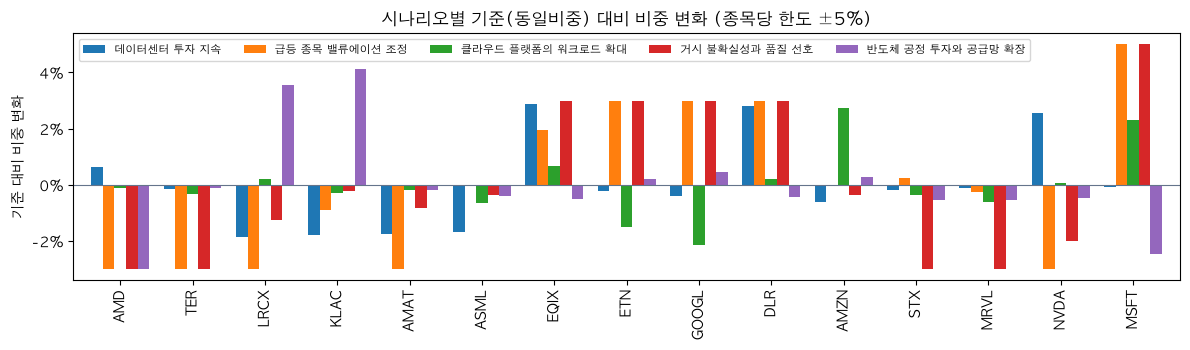

In [6]:
sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                    "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in P["targets"]["portfolios"]])
display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
dl = pd.DataFrame({p["title_ko"]: p["delta_vs_baseline"] for p in P["targets"]["portfolios"]})
ax = dl.plot.bar(figsize=(12, 3.6), width=0.8); ax.axhline(0, color="#64748b", lw=0.8); ax.set_ylabel("기준 대비 비중 변화"); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title(f"시나리오별 기준(동일비중) 대비 비중 변화 (종목당 한도 ±{P['targets']['parameters']['max_tilt_per_stock']:.0%})"); ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

## 5. 백테스트 — 같은 기간·같은 적립으로 9개 포트폴리오와 비교지수를 돌린 결과

In [7]:
BT = R["backtest"]; rec = R["validation"].get("recommended"); chosen = rec["id"] if rec else P["targets"]["baseline"]["id"]
label = lambda p: (f"시나리오: {p['title_ko']}" if p.get("title_ko") else p["name_ko"])
E = BT["engine"]; print(f"기간 {BT['period']['start']}~{BT['period']['end']} ({BT['period']['trading_days']}거래일) · 적립 {E['n_contributions']}회 × {E['contribution_usd']:.0f} USD · 거래비용 {E['commission_bps']}bp · 무위험 {E['risk_free_rate']:.0%} · {E['prices']}")
print("중심 포트폴리오:", chosen, "(추천)" if rec else "(추천 없음 → 기준 포트폴리오)")
rows = []
for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]:
    h, m = p["headline"], p["metrics"]
    rows.append({"포트폴리오": label(p), "종류": p["kind"], "누적수익": m["return"]["total_return"], "CAGR": h["cagr"], "변동성": m["risk"]["ann_vol"], "Sharpe": h["sharpe"], "최대낙폭": h["max_drawdown"],
                 "SPY 대비": h["excess_cagr"], "최종 평가금액": h["final_value_usd"], "투입 원금": p["money"]["net_invested_usd"], "XIRR": p["money"]["irr_annual"], "뷰 적중": h["view_hit_ratio"]})
comp = pd.DataFrame(rows).set_index("포트폴리오")
display(comp.style.format({"누적수익": "{:+.1%}", "CAGR": "{:+.1%}", "변동성": "{:.1%}", "Sharpe": "{:.2f}", "최대낙폭": "{:.1%}", "SPY 대비": "{:+.1%}", "최종 평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "XIRR": "{:+.1%}", "뷰 적중": "{:.0%}"}, na_rep="–").background_gradient(subset=["Sharpe"], cmap="Blues"))

기간 2020-01-02~2026-10-09 (1702거래일) · 적립 80회 × 433 USD · 거래비용 5bp · 무위험 4% · adj_close (dividends reinvested)
중심 포트폴리오: equal_weight (추천 없음 → 기준 포트폴리오)


,종류,누적수익,CAGR,변동성,Sharpe,최대낙폭,SPY 대비,최종 평가금액,투입 원금,XIRR,뷰 적중
포트폴리오,,,,,,,,,,,
시나리오: 데이터센터 투자 지속,black_litterman,+519.1%,+31.0%,27.8%,0.97,-42.9%,+15.7%,"158,053","43,329",+32.1%,100%
시나리오: 급등 종목 밸류에이션 조정,black_litterman,+395.3%,+26.7%,25.8%,0.88,-38.6%,+11.5%,"132,882","43,329",+27.7%,0%
시나리오: 클라우드 플랫폼의 워크로드 확대,black_litterman,+508.7%,+30.7%,28.2%,0.95,-42.5%,+15.4%,"156,385","43,329",+31.9%,100%
시나리오: 거시 불확실성과 품질 선호,black_litterman,+380.8%,+26.2%,25.9%,0.86,-38.4%,+10.9%,"127,508","43,329",+26.7%,25%
시나리오: 반도체 공정 투자와 공급망 확장,black_litterman,+548.7%,+31.9%,29.3%,0.95,-42.1%,+16.6%,"165,479","43,329",+33.3%,75%
동일비중,template,+539.3%,+31.6%,28.6%,0.97,-42.7%,+16.3%,"163,427","43,329",+33.0%,–
시가총액비중,template,+513.9%,+30.8%,27.8%,0.97,-42.2%,+15.6%,"153,647","43,329",+31.4%,–
역변동성비중,template,+505.5%,+30.6%,28.1%,0.94,-41.8%,+15.3%,"156,268","43,329",+31.8%,–
최소분산,template,+402.5%,+27.0%,25.6%,0.90,-38.9%,+11.7%,"134,811","43,329",+28.1%,–


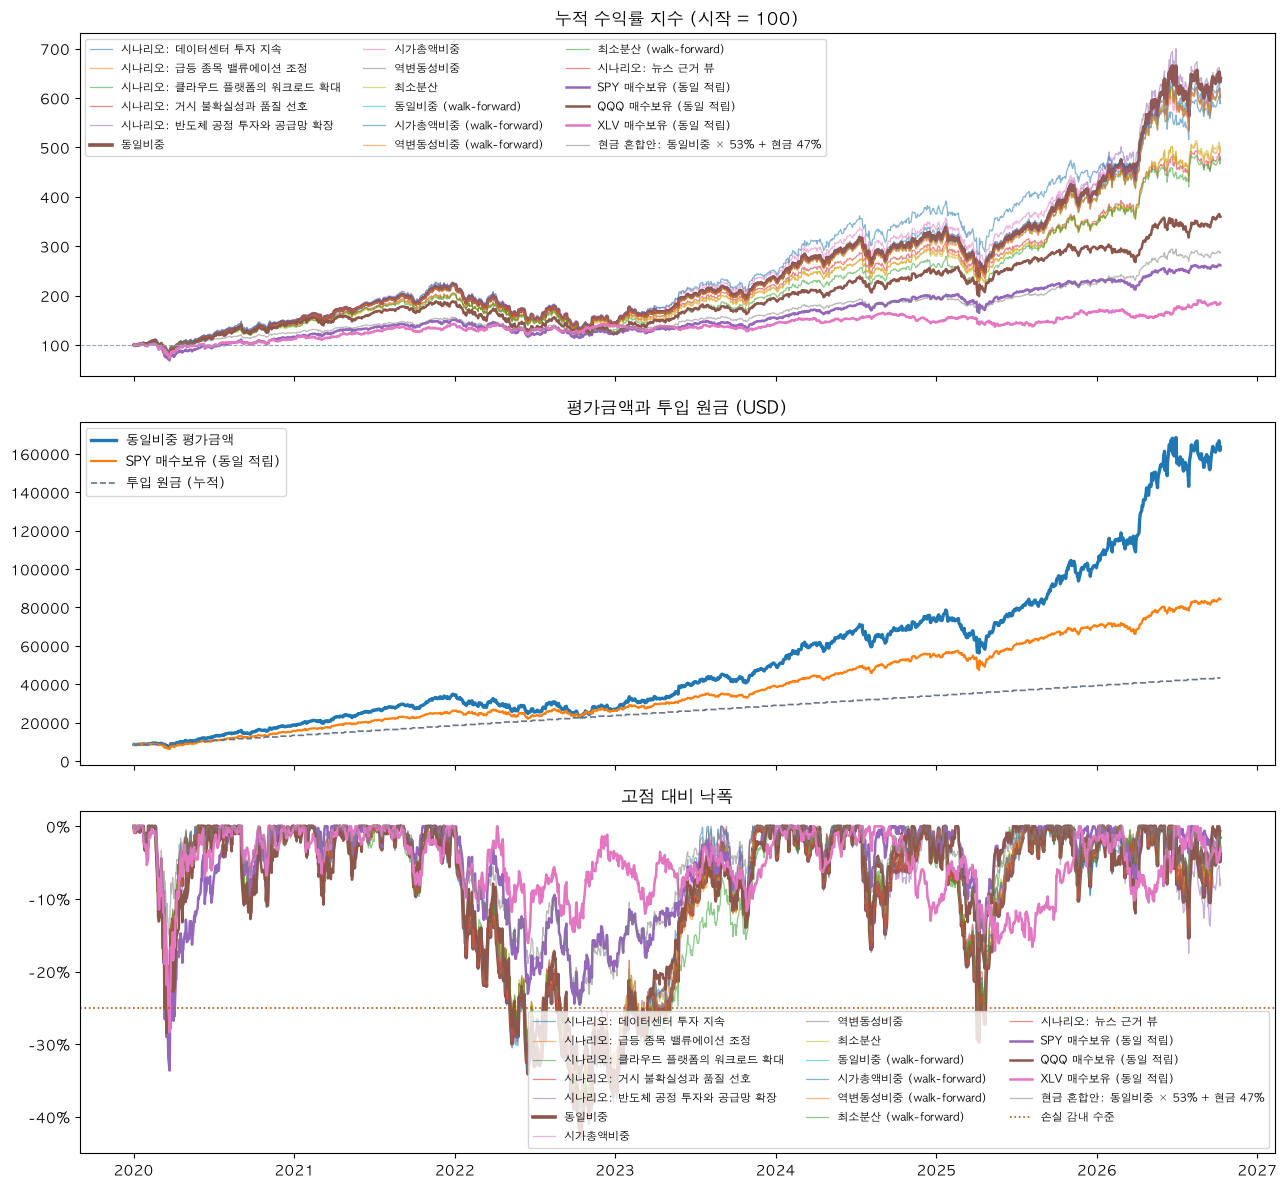

동일비중 최대낙폭 -42.7%: 고점 2021-12-27 → 저점 2022-10-14 → 회복 2023-11-20 (고점 아래 693일)


In [8]:
dates = pd.to_datetime(BT["series_dates"]); series = {p["id"]: p for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]}
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for pid, p in series.items():
    lw = 2.6 if pid == chosen else (1.8 if p["kind"] == "benchmark" else 0.9); alpha = 1 if (pid == chosen or p["kind"] == "benchmark") else 0.55
    axes[0].plot(dates, p["series"]["index"], lw=lw, alpha=alpha, label=label(p))
    axes[2].plot(dates, p["series"]["drawdown"], lw=lw, alpha=alpha, label=label(p))
axes[0].axhline(100, color="#94a3b8", ls="--", lw=0.8); axes[0].set_title("누적 수익률 지수 (시작 = 100)"); axes[0].legend(ncol=3, fontsize=8)
cp = series[chosen]; led = {l["date"]: l["amount_usd"] for l in cp["contribution_ledger"]}; inv, cum = [], cp["money"]["initial_usd"]
for ds in BT["series_dates"]: cum += led.get(ds, 0.0); inv.append(cum)
axes[1].plot(dates, cp["series"]["value_usd"], lw=2.4, label=f"{label(cp)} 평가금액"); axes[1].plot(dates, series[BT["benchmark"]["id"]]["series"]["value_usd"], lw=1.6, label="SPY 매수보유 (동일 적립)")
axes[1].plot(dates, inv, lw=1.2, ls="--", color="#64748b", label="투입 원금 (누적)"); axes[1].set_title("평가금액과 투입 원금 (USD)"); axes[1].legend(fontsize=9)
axes[2].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); axes[2].set_title("고점 대비 낙폭"); axes[2].axhline(-R["intent"]["risk_params"]["effective_max_drawdown"], color="#b45309", ls=":", lw=1.2, label="손실 감내 수준")
axes[2].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()
mdd = cp["metrics"]["risk"]["mdd"]; print(f"{label(cp)} 최대낙폭 {cp['headline']['max_drawdown']:.1%}: 고점 {mdd['peak_date']} → 저점 {mdd['trough_date']} → 회복 {mdd['recovery_date'] or '기간 내 미회복'} (고점 아래 {mdd['underwater_days']}일)")

,2020,2021,2022,2023,2024,2025,2026
동일비중,+48.5%,+49.1%,-35.0%,+64.2%,+32.0%,+29.9%,+57.8%
SPY 매수보유 (동일 적립),+17.0%,+28.8%,-18.2%,+26.2%,+24.9%,+17.7%,+14.4%


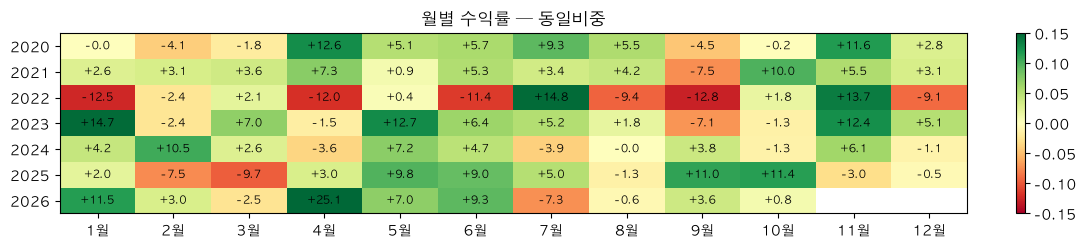

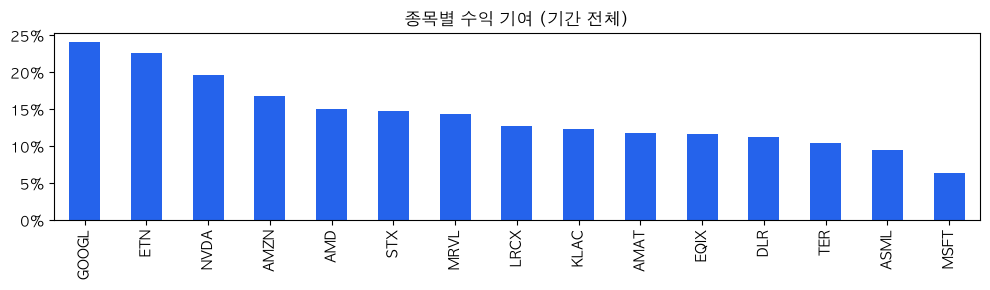

In [9]:
yr = pd.DataFrame({label(p): p["yearly_returns"] for p in [cp, series[BT["benchmark"]["id"]], series[P["targets"]["baseline"]["id"]]]}).T
display(yr.style.format("{:+.1%}", na_rep="–").set_caption("연도별 수익률 (첫해·마지막 해는 부분 기간)"))
mr = pd.DataFrame(cp["monthly_returns"]).pivot(index="year", columns="month", values="return")
fig, ax = plt.subplots(figsize=(11, 2.6)); im = ax.imshow(mr.values, cmap="RdYlGn", vmin=-0.15, vmax=0.15, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels([f"{m}월" for m in range(1, 13)]); ax.set_yticks(range(len(mr.index))); ax.set_yticklabels(mr.index)
for i in range(mr.shape[0]):
    for j in range(mr.shape[1]):
        v = mr.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v*100:+.1f}", ha="center", va="center", fontsize=8)
ax.set_title(f"월별 수익률 — {label(cp)}"); plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout(); plt.show()
contrib = pd.Series(cp["ticker_contribution"]).sort_values(ascending=False)
ax = contrib.plot.bar(figsize=(10, 3), color=["#2563eb" if v >= 0 else "#b45309" for v in contrib]); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); ax.set_title("종목별 수익 기여 (기간 전체)"); plt.tight_layout(); plt.show()

### 리밸런싱 시점별 구성과 성과
각 리밸런싱일의 **조정 후 비중**(행)과 그 **직전 구간 성과**, 그 시점까지의 누적 지표입니다.

In [10]:
cps = cp["checkpoints"]
wt = pd.DataFrame({c["date"]: c["weights"]["after"] for c in cps}).T
display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption(f"리밸런싱 후 비중 — {label(cp)}"))
rows = []
for c in cps:
    sl, td = c["since_last"] or {}, c["to_date"] or {}
    rows.append({"날짜": c["date"], "구분": c["kind"], "평가금액": c["money"]["value_usd"], "투입 원금": c["money"]["net_invested_usd"], "구간 수익": sl.get("return"), "SPY 구간": sl.get("benchmark_return"),
                 "구간 최대낙폭": sl.get("max_drawdown"), "최고 종목": f"{sl['best']['ticker']} {sl['best']['return']:+.1%}" if sl else "", "최저 종목": f"{sl['worst']['ticker']} {sl['worst']['return']:+.1%}" if sl else "",
                 "누적 CAGR": td.get("cagr"), "누적 MDD": td.get("max_drawdown"), "누적 Sharpe": td.get("sharpe"), "거래": len(c["trades"]), "비용": c["commission_usd"]})
display(pd.DataFrame(rows).set_index("날짜").style.format({"평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "구간 수익": "{:+.1%}", "SPY 구간": "{:+.1%}", "구간 최대낙폭": "{:.1%}", "누적 CAGR": "{:+.1%}", "누적 MDD": "{:.1%}", "누적 Sharpe": "{:.2f}", "비용": "{:.2f}"}, na_rep="–"))

,AMD,TER,LRCX,KLAC,AMAT,ASML,EQIX,ETN,GOOGL,DLR,AMZN,STX,MRVL,NVDA,MSFT
2020-01-02,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2020-04-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2020-07-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2020-10-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2021-01-04,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2021-04-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2021-07-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2021-10-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2022-01-03,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2022-04-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%


,구분,평가금액,투입 원금,구간 수익,SPY 구간,구간 최대낙폭,최고 종목,최저 종목,누적 CAGR,누적 MDD,누적 Sharpe,거래,비용
날짜,,,,,,,,,,,,,
2020-01-02,rebalance,"8,661","8,666",–,–,–,,,–,–,–,15,4.33
2020-04-01,rebalance,"8,611","9,532",-10.0%,-23.7%,-27.8%,DLR +14.9%,AMAT -30.2%,-35.0%,-27.8%,-0.64,15,0.59
2020-07-01,rebalance,"12,814","10,832",+32.4%,+26.5%,-5.5%,MRVL +59.3%,STX +0.1%,+42.2%,-27.8%,0.79,15,0.66
2020-10-01,rebalance,"15,464","12,132",+10.2%,+8.9%,-12.0%,AMD +61.4%,TER -1.8%,+43.7%,-27.8%,0.95,15,0.60
2021-01-04,rebalance,"18,614","13,432",+11.7%,+9.9%,-7.5%,TER +46.7%,EQIX -9.5%,+46.3%,-27.8%,1.13,15,1.18
2021-04-01,rebalance,"22,585","14,732",+14.0%,+9.0%,-9.1%,AMAT +63.2%,AMD -12.1%,+50.9%,-27.8%,1.34,15,1.23
2021-07-01,rebalance,"26,299","16,032",+10.4%,+7.8%,-6.8%,NVDA +46.3%,KLAC -10.0%,+50.6%,-27.8%,1.42,15,0.79
2021-10-01,rebalance,"27,773","17,332",+0.9%,+1.2%,-8.4%,GOOGL +11.5%,TER -15.3%,+42.6%,-27.8%,1.25,15,0.72
2022-01-03,rebalance,"34,528","18,631",+19.4%,+10.4%,-4.0%,TER +51.8%,AMZN +3.8%,+48.9%,-27.8%,1.52,15,1.82


In [11]:
vd = [(label(p), v["type"], v["summary_ko"].split(" — ")[0], v["expected_return_annual"], v["realized"], "적중" if v["hit"] else "빗나감") for p in BT["portfolios"] for v in p["view_diagnostics"]]
if vd:
    display(pd.DataFrame(vd, columns=["시나리오", "유형", "뷰", "기대", "실제(12개월)", "방향"]).style.format({"기대": "{:+.0%}", "실제(12개월)": "{:+.1%}"}).set_caption("시나리오 뷰 사후 점검 (구성 후 12개월 실현 수익)"))

,시나리오,유형,뷰,기대,실제(12개월),방향
0,시나리오: 데이터센터 투자 지속,absolute,[절대] NVDA +41%/년 (신뢰 0.38),+41%,+118.1%,적중
1,시나리오: 데이터센터 투자 지속,relative,[상대] LRCX+KLAC > EQIX +9%/년 (신뢰 0.34),+9%,+27.6%,적중
2,시나리오: 데이터센터 투자 지속,absolute,[절대] AMD +44%/년 (신뢰 0.31),+44%,+86.8%,적중
3,시나리오: 데이터센터 투자 지속,relative,[상대] AMAT+ASML > DLR +8%/년 (신뢰 0.32),+8%,+29.3%,적중
4,시나리오: 급등 종목 밸류에이션 조정,absolute,[절대] AMD +31%/년 (신뢰 0.29),+31%,+86.8%,빗나감
5,시나리오: 급등 종목 밸류에이션 조정,relative,[상대] MSFT+GOOGL > AMD+NVDA +7%/년 (신뢰 0.33),+7%,-68.4%,빗나감
6,시나리오: 급등 종목 밸류에이션 조정,absolute,[절대] EQIX +8%/년 (신뢰 0.27),+8%,+25.2%,빗나감
7,시나리오: 급등 종목 밸류에이션 조정,relative,[상대] ETN+DLR > TER+LRCX +6%/년 (신뢰 0.28),+6%,-41.3%,빗나감
8,시나리오: 클라우드 플랫폼의 워크로드 확대,absolute,[절대] AMZN +28%/년 (신뢰 0.34),+28%,+71.6%,적중
9,시나리오: 클라우드 플랫폼의 워크로드 확대,relative,[상대] AMZN+MSFT > EQIX +8%/년 (신뢰 0.33),+8%,+30.6%,적중


## 6. 검증 — 사용자 기준(손실 감내 수준·목표 수익·제약)에 비춰 본 판정

In [12]:
V = R["validation"]; print("기준:", {k: V["criteria"][k] for k in ["max_drawdown", "target_annual_return", "benchmark", "volatility_preference", "max_weight_per_stock", "max_weight_per_sector", "min_holdings"]})
mat = pd.DataFrame({label(series[r["id"]]): {c["rule"] + " " + c["name_ko"]: c["status"] for c in r["checks"]} for r in V["results"]}).T
color = lambda s: "background-color:#dcfce7" if s == "pass" else ("background-color:#fef3c7" if s == "warn" else "background-color:#fee2e2")
display(mat.style.map(color).set_caption("규칙별 판정 (pass 통과 / warn 주의 / fail 미통과)"))
print("요약:", V["summary"]); print("추천:", V["recommended"]["id"] + " — " + V["recommended"]["reason_ko"] if V["recommended"] else "추천 없음 — " + "; ".join(V["warnings"]))
for alt in V.get("alternatives", []): print(f"대안 {alt['name_ko']}: {alt['reason_ko']} 판정 {alt['status']}")
inf = V["criteria"].get("selection_infeasibility")
if inf: print(f"종목 수 미달 사유: 섹터 상한 {inf['sector_cap']:.0%} 로 최대 {inf['max_feasible_n']}종목 (목표 {inf['target']}); 선택지: " + " / ".join(inf["options_ko"]))
chk = pd.DataFrame(next(r for r in V["results"] if r["id"] == chosen)["checks"])[["rule", "name_ko", "level", "status", "message_ko"]]
display(chk.set_index("rule").rename(columns={"name_ko": "항목", "level": "수준", "status": "판정", "message_ko": "측정 결과"}).style.set_caption(f"{label(cp)} 상세"))

기준: {'max_drawdown': 0.25, 'target_annual_return': 0.12, 'benchmark': 'SPY', 'volatility_preference': 'medium', 'max_weight_per_stock': 0.15, 'max_weight_per_sector': 0.4, 'min_holdings': 10}


,R1 최대낙폭,R2 목표수익,R3 비교지수 대비,R4 종목 상한(리밸런싱일),R4b 종목 상한(드리프트),R5 섹터 상한(리밸런싱일),R5b 섹터 상한(드리프트),R6 종목 수,R7 변동성 적합,R8 데이터 무결성
시나리오: 데이터센터 투자 지속,fail,pass,pass,pass,warn,pass,pass,pass,pass,pass
시나리오: 급등 종목 밸류에이션 조정,fail,pass,pass,pass,warn,pass,pass,pass,pass,pass
시나리오: 클라우드 플랫폼의 워크로드 확대,fail,pass,pass,pass,pass,pass,warn,pass,pass,pass
시나리오: 거시 불확실성과 품질 선호,fail,pass,pass,pass,warn,pass,pass,pass,pass,pass
시나리오: 반도체 공정 투자와 공급망 확장,fail,pass,pass,pass,pass,pass,warn,pass,pass,pass
동일비중,fail,pass,pass,pass,pass,pass,warn,pass,pass,pass
시가총액비중,fail,pass,pass,pass,warn,pass,pass,pass,pass,pass
역변동성비중,fail,pass,pass,pass,pass,pass,warn,pass,pass,pass
최소분산,fail,pass,pass,pass,warn,pass,pass,pass,pass,pass
동일비중 (walk-forward),fail,pass,pass,pass,pass,pass,warn,pass,pass,pass


요약: {'n_pass': 0, 'n_warn': 0, 'n_fail': 14}
추천: 추천 없음 — no portfolio passed the hard rules (fail counts by rule: {'R1': 14}); recommended=null
대안 현금 혼합안: 동일비중 × 53% + 현금 47%: 동일비중의 과거 최대낙폭이 허용 25%를 넘어, 같은 종목 비중을 53%로 줄이고 47%를 현금(수익 0 가정)으로 두었을 때의 결과입니다. 실제 백테스트 최대낙폭 -24.7%, CAGR 16.9%. 판정 pass


,항목,수준,판정,측정 결과
rule,,,,
R1,최대낙폭,hard,fail,최대낙폭 42.7% > 허용 25%
R2,목표수익,soft,pass,CAGR 31.6% vs 목표 12%
R3,비교지수 대비,soft,pass,SPY 대비 초과 CAGR +16.3%
R4,종목 상한(리밸런싱일),hard,pass,리밸런싱일 최대 종목 비중 12.0% vs 상한 15%
R4b,종목 상한(드리프트),soft,pass,리밸런싱 사이 종목 비중 드리프트 허용 범위 안
R5,섹터 상한(리밸런싱일),hard,pass,리밸런싱일 최대 섹터 비중 40.0% vs 상한 40%
R5b,섹터 상한(드리프트),soft,warn,리밸런싱 사이 섹터 드리프트 초과
R6,종목 수,hard,pass,보유 종목 15개 vs 최소 10개
R7,변동성 적합,soft,pass,연변동성 28.6% vs 성향(medium) 상한 30%


## 6b. 뉴스가 바꾼 것 — walk-forward (리밸런싱마다 직전 2주 뉴스로 뷰를 새로 만든 결과)

In [13]:
WF = R["portfolio"].get("walkforward"); EVD = (R["portfolio"].get("news_evidence") or {}).get("all_evidence", {})
if not WF:
    print("walk-forward 결과 없음 (--news 로 실행한 경우에만 생성)")
else:
    bl = next(p for p in WF["portfolios"] if p["kind"] == "black_litterman"); base = next(p for p in WF["portfolios"] if p["id"] == "wf_equal_weight")
    rows = []
    for d in WF["dates"]:
        ns = WF["news_summary"][d]; views = bl["views_by_date"].get(d, []); w = bl["weights_by_date"][d]; b = base["weights_by_date"][d]
        top = sorted(((t, w[t] - b[t]) for t in w), key=lambda x: -abs(x[1]))[:3]
        rows.append({"리밸런싱일": d, "뉴스 창": f"{ns['window'][0]}~{ns['window'][1]}", "기사": ns["n_articles"], "뉴스 있는 종목": ns["n_tickers_with_news"],
                     "출처": ", ".join(f"{k} {v}" for k, v in ns["origin_counts"].items() if v), "뷰": len(views), "기준 대비 변화(상위 3)": ", ".join(f"{t} {x:+.1%}" for t, x in top) if views else "기준 비중 유지"})
    display(pd.DataFrame(rows).set_index("리밸런싱일"))
    vrows = [{"날짜": d, "뷰": v["summary_ko"].split(" — ")[0], "신뢰도": v["confidence"], "근거": ", ".join(v.get("evidence_ids", [])), "이유": v.get("rationale_ko", "")} for d in WF["dates"] for v in bl["views_by_date"].get(d, [])]
    if vrows: display(pd.DataFrame(vrows).set_index("날짜"))
    used = sorted({i for d in WF["dates"] for v in bl["views_by_date"].get(d, []) for i in v.get("evidence_ids", [])})
    if used:
        erows = [{"근거": i, "날짜": EVD[i]["published_at"], "종목": EVD[i]["ticker"], "출처": "팀 DB" if EVD[i].get("origin", "db") == "db" else "웹 검색", "발행사": EVD[i].get("publisher") or EVD[i].get("source"), "제목": EVD[i]["title"][:90], "url": EVD[i]["url"]} for i in used if i in EVD]
        display(pd.DataFrame(erows).set_index("근거"))
    wt = pd.DataFrame({d: bl["weights_by_date"][d] for d in WF["dates"]}).T
    display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption("뉴스 뷰 BL — 리밸런싱일별 타겟 비중"))
    for pid in [bl["id"], "wf_equal_weight"]:
        p = series.get(pid)
        if p: print(f"{p['name_ko']}: 기간 수익률 {p['headline']['period_return']:+.2%}, 최대낙폭 {p['headline']['max_drawdown']:.2%}, 최종 {p['headline']['final_value_usd']:,.0f} USD")

,뉴스 창,기사,뉴스 있는 종목,출처,뷰,기준 대비 변화(상위 3)
리밸런싱일,,,,,,
2020-01-02,2019-12-19~2020-01-02,0,0,,0,기준 비중 유지
2020-04-01,2020-03-18~2020-04-01,0,0,,0,기준 비중 유지
2020-07-01,2020-06-17~2020-07-01,0,0,,0,기준 비중 유지
2020-10-01,2020-09-17~2020-10-01,0,0,,0,기준 비중 유지
2021-01-04,2020-12-21~2021-01-04,0,0,,0,기준 비중 유지
2021-04-01,2021-03-18~2021-04-01,0,0,,0,기준 비중 유지
2021-07-01,2021-06-17~2021-07-01,0,0,,0,기준 비중 유지
2021-10-01,2021-09-17~2021-10-01,0,0,,0,기준 비중 유지
2022-01-03,2021-12-20~2022-01-03,0,0,,0,기준 비중 유지


,뷰,신뢰도,근거,이유
날짜,,,,
2026-10-01,[절대] EQIX +14%/년 (신뢰 0.35),0.35,"ev11945, ev11940",Equinix의 AI·상호연결 수요가 가속화되고 있다는 보도와 RBC 행사에서 AI 수요가 성장 전망을 높인다는 헤드라인을 근거로 합니다...
2026-10-01,[절대] AMZN +10%/년 (신뢰 0.30),0.30,"ev8580, ev8583, ev8582","AWS의 데이터 기능 업데이트와 Synopsys와의 칩 설계 라이선스 계약, 데이터센터 전력 지원을 위한 20년 계약 보도가 클라우드 인..."
2026-10-01,[상대] AMAT > AMD +4%/년 (신뢰 0.20),0.20,"ev8390, ev8444, ev8447","AMAT의 Kioxia와의 차세대 AI 메모리 기술 협력 보도가 있는 반면, AMD의 World Labs 관련 대형 투자 보도에는 AI ..."
2026-10-01,[상대] DLR > ETN +5%/년 (신뢰 0.25),0.25,"ev11354, ev11352, ev12054, ev12051","Digital Realty의 AI 기반 기록적 상호연결 수요와 AI 추론 플랫폼의 데이터센터 선정 보도를, Eaton의 밸류에이션이 프리..."


,날짜,종목,출처,발행사,제목,url
근거,,,,,,
ev11352,2026-09-30,DLR,팀 DB,marketscreener.com,Digital Realty's Barcelona Data Center to Serve as Foundation for Blackfuel'...,https://news.google.com/rss/articles/CBMi5wFBVV95cUxOMXJweWZOMVZkRGdZM05RWUt...
ev11354,2026-09-30,DLR,팀 DB,MarketBeat,Digital Realty Sees Agentic AI Fuel Record Interconnection Demand,https://news.google.com/rss/articles/CBMiwwFBVV95cUxQZHQtSnFpWjExdHhEZnV1MnN...
ev11940,2026-09-29,EQIX,팀 DB,Investing.com,Equinix at RBC Capital Markets conference: ai demand lifts outlook,https://news.google.com/rss/articles/CBMivgFBVV95cUxPLXdwYnZQanMySUh5Qk83eVl...
ev11945,2026-09-30,EQIX,팀 DB,MarketBeat,"Equinix Says AI, Interconnection Demand Is Accelerating Growth",https://news.google.com/rss/articles/CBMivgFBVV95cUxQOUdEWFcwTDlrdkdUV2luc21...
ev12051,2026-09-30,ETN,팀 DB,Simply Wall Street,Eaton (ETN) Following COL Group Deal Is Its Valuation Back In Focus,https://news.google.com/rss/articles/CBMiwwFBVV95cUxQTUZqOWNJZXB3OVNraXp2Qjc...
ev12054,2026-09-30,ETN,팀 DB,Zacks Investment Research,Eaton Trades at a Premium to Industry: What Investors Should Know,https://news.google.com/rss/articles/CBMiqAFBVV95cUxQZFpYNE9pVmNyWHJKRVY3MUs...
ev8390,2026-09-29,AMAT,팀 DB,Yahoo Finance,"Applied Materials, Kioxia Collaborate to Develop AI Memory Technology",https://news.google.com/rss/articles/CBMirAFBVV95cUxQNUJnVFdYRlhtc0EtSk8tLXN...
ev8444,2026-09-30,AMD,팀 DB,Yahoo Finance,Advanced Micro Devices (AMD) Is Spending $8.2 Billion On World Labs,https://news.google.com/rss/articles/CBMioAFBVV95cUxPaVgzYTV6SHRzQkVpTEg2NVF...
ev8447,2026-09-30,AMD,팀 DB,Simply Wall Street,Advanced Micro Devices (AMD) After World Labs Deal Is The AI Story Already P...,https://news.google.com/rss/articles/CBMi3wFBVV95cUxPYW1lM2VreW5TOG5Kdm1QZ1h...


,AMD,TER,LRCX,KLAC,AMAT,ASML,EQIX,ETN,GOOGL,DLR,AMZN,STX,MRVL,NVDA,MSFT
2020-01-02,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2020-04-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2020-07-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2020-10-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2021-01-04,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2021-04-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2021-07-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2021-10-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2022-01-03,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2022-04-01,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%


뉴스 뷰 Black-Litterman (walk-forward): 기간 수익률 +540.53%, 최대낙폭 -42.72%, 최종 163,735 USD
동일비중 (walk-forward): 기간 수익률 +539.33%, 최대낙폭 -42.72%, 최종 163,427 USD


## 6c. 지금 구성한다면 — 최신 가격·뉴스 기준 (백테스트 없음)

기준일 2026-10-09 · 뉴스 창 2026-09-25~2026-10-09 · 기사 150건 · 뉴스 있는 종목 15 · δ=7.5752 (market_implied)


,관점,뷰,근거 수,최대 변화,예상 수익,예상 변동성
시나리오,,,,,,
AI 광통신·포토닉스 수요와 밸류에이션 부담,"Lumentum 관련 헤드라인은 AI 수요와 Nvidia의 광학 전환 움직임을 언급하는 한편, 주가 급등과 추가 돌파 보도도 포함합니다. Coherent에는 주가 하락 및 고평가를 거론한 제목이 있어 광통신 종목 안",[절대] LITE +18%/년 (신뢰 0.30) / [절대] COHR -8%/년 (신뢰 0.20) / [상대] LITE > COHR +8%/년 (신뢰 0.25) / [상대] LITE > INTC +4%/년 (신뢰 0.20),5,+5.0%,58.8%,29.3%
AI 메모리 강세와 HDD 경쟁 변수,"Micron 관련 제목에는 AI 메모리 붐 기대와 함께 AI 자본지출 지속 가능성 논쟁, 파업 승인 및 공장 위협이 함께 나타납니다. HDD 업체에는 Toshiba의 확장 및 경쟁 우려가 보도되어, 메모리와 저장장치",[절대] MU +16%/년 (신뢰 0.25) / [절대] WDC -8%/년 (신뢰 0.25) / [상대] MU > STX +8%/년 (신뢰 0.25) / [상대] MU > WDC +7%/년 (신뢰 0.25),10,+5.0%,58.3%,29.3%
AI 서버 제품화와 반도체 테스트 수요,"Dell은 AI 데이터 플랫폼 기능과 agentic AI용 PC·워크스테이션을 발표했다는 보도가 있습니다. Teradyne에는 AI 칩 신뢰성 테스트 기능 강화와 플랫폼 출시가 보도된 반면, Intel 관련 헤드라인",[절대] DELL +12%/년 (신뢰 0.25) / [절대] TER +12%/년 (신뢰 0.25) / [상대] DELL > INTC +4%/년 (신뢰 0.20) / [상대] TER > INTC +5%/년 (신뢰 0.20),7,+5.0%,65.7%,30.7%
데이터센터 전력·설비 수요와 대체 전원 리스크,Eaton에는 데이터센터 변압기 부족과 장기 수주잔고를 언급한 보도가 있어 전력 설비 수요에 주목했습니다. Bloom Energy에는 데이터센터의 천연가스 사용 보도와 프로젝트 시점 불확실성을 거론한 제목이 있는 반,[절대] ETN +14%/년 (신뢰 0.30) / [절대] BE -12%/년 (신뢰 0.25) / [상대] ETN > BE +9%/년 (신뢰 0.25) / [상대] VRT > BE +5%/년 (신뢰 0.20),5,+5.0%,55.4%,29.0%
클라우드 플랫폼 전략과 데이터센터 확장 변수,"Alphabet 관련 제목에는 AI 성장 기대와 기존 사업을 대체할 수 있는 기술에 대한 논의, 주주 소송 보도가 함께 있습니다. Amazon에는 AI 쇼핑 에이전트 차단과 지역 데이터센터 계획을 둘러싼 긴장 보도가",[절대] GOOGL +8%/년 (신뢰 0.20) / [절대] AMZN -5%/년 (신뢰 0.20) / [상대] GOOGL > AMZN +4%/년 (신뢰 0.20) / [상대] EQIX > DLR +3%/년 (신뢰 0.20),7,+5.0%,79.2%,33.6%


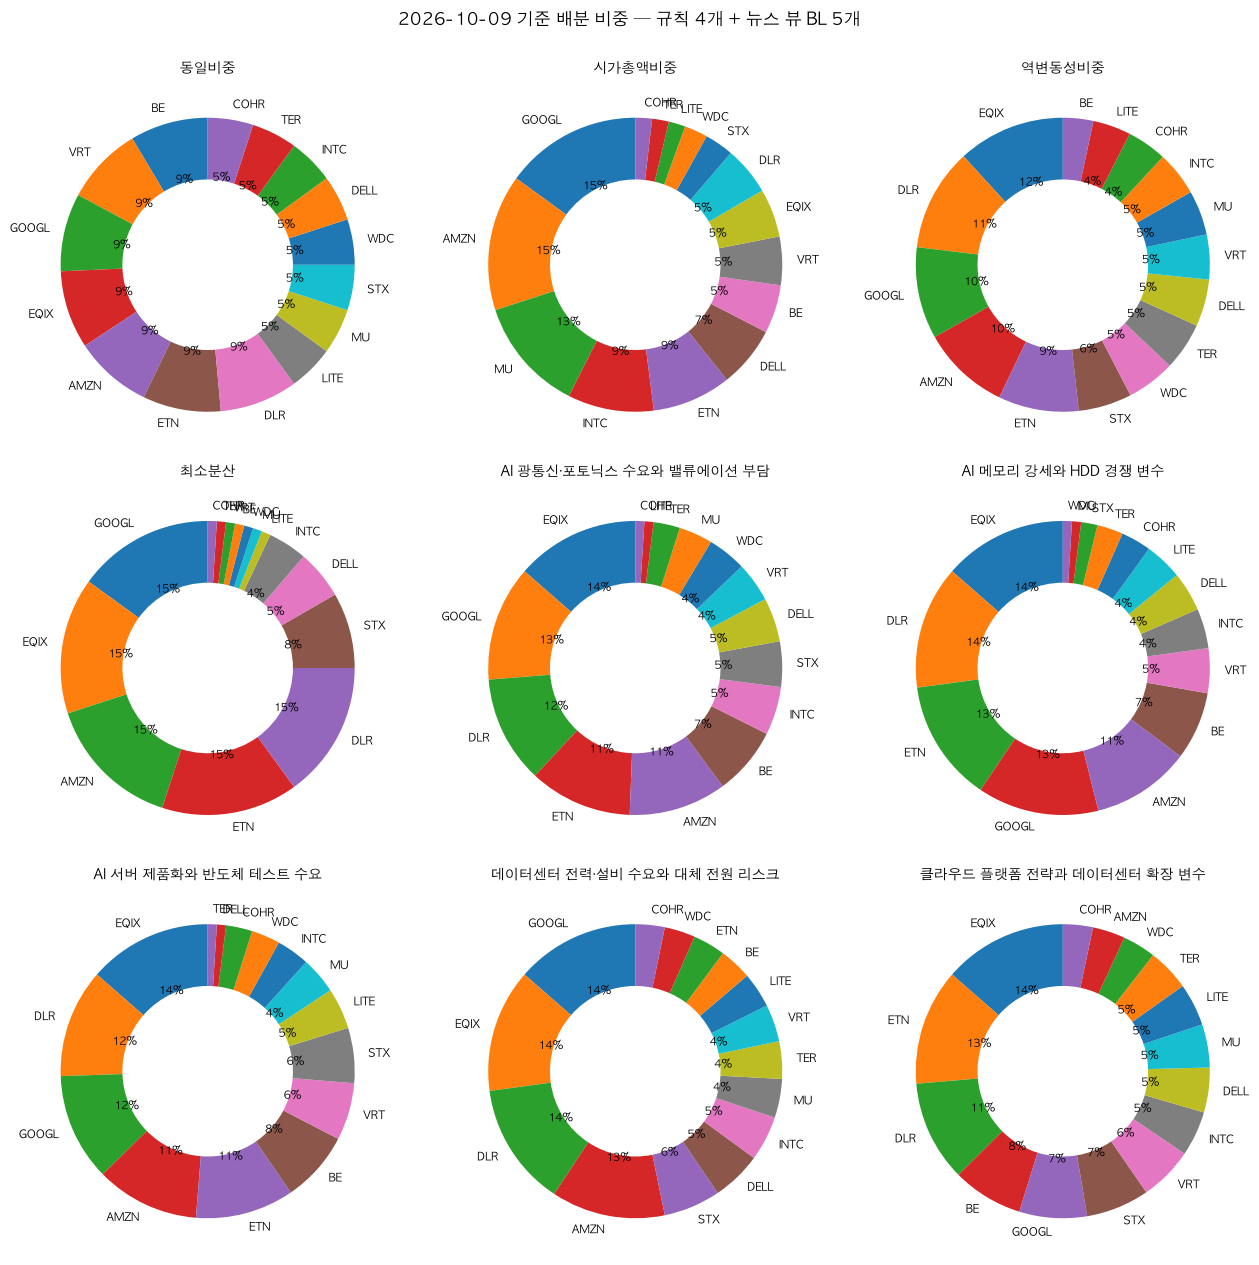

,비중,USD,원화
티커,,,
EQIX,13.6%,"1,012.78","1,357,141"
GOOGL,12.7%,947.26,"1,269,351"
DLR,11.8%,881.22,"1,180,851"
ETN,11.3%,845.27,"1,132,681"
AMZN,10.7%,802.00,"1,074,701"
BE,7.5%,557.11,"746,540"
INTC,5.3%,396.09,"530,770"
STX,5.0%,373.25,"500,160"
DELL,4.8%,360.38,"482,910"


In [14]:
F = R["portfolio"].get("forward")
if not F:
    print("현재 구성 결과 없음")
else:
    nw = F.get("news_window"); print(f"기준일 {F['as_of']} · 뉴스 창 {nw['window'][0]}~{nw['window'][1]} · 기사 {nw['n_articles']}건 · 뉴스 있는 종목 {nw['n_tickers_with_news']} · δ={F['market_model']['delta']} ({F['market_model']['delta_source']})" if nw else f"기준일 {F['as_of']}")
    sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0][:120], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                        "근거 수": len({i for v in p["views_applied"] for i in v.get("evidence_ids", [])}), "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in F["portfolios"]])
    display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
    ports = F["templates"] + F["portfolios"]
    cols = 3; rows_ = -(-len(ports) // cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(13, 4.2 * rows_))
    for ax, p in zip(axes.flat, ports):
        items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
        ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
        ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=10)
    for ax in list(axes.flat)[len(ports):]: ax.axis("off")
    plt.suptitle(f"{F['as_of']} 기준 배분 비중 — 규칙 4개 + 뉴스 뷰 BL {len(F['portfolios'])}개", y=1.0); plt.tight_layout(); plt.show()
    chosen = F["portfolios"][0] if F["portfolios"] else F["templates"][0]
    display(pd.DataFrame(chosen["allocation"]).rename(columns={"ticker": "티커", "weight": "비중", "usd": "USD", "krw": "원화"}).set_index("티커").style.format({"비중": "{:.1%}", "USD": "{:,.2f}", "원화": "{:,.0f}"}).set_caption(f"배분 금액 — {chosen['name_ko']} (투자금 {F['capital']['initial_amount_usd']:,.0f} USD)"))

## 7. 비용·조건·경고

In [15]:
u = R["llm_usage"]
if u.get("available"):
    display(pd.DataFrame(u["by_stage"]).T.style.format({"cost_usd": "{:.4f}"}).set_caption(f"분석 모델 호출 (누적, {u['model']}) — 합계 {u['total_cost_usd']:.4f} USD"))
display(pd.DataFrame(R["sources"])[["name", "what"]].rename(columns={"name": "출처", "what": "사용한 내용"}).set_index("출처"))
print("파라미터:", json.dumps(R["parameters"], ensure_ascii=False)[:600])
pd.DataFrame(R["warnings"]).rename(columns={"stage": "단계", "message": "경고"})

,calls,prompt_tokens,completion_tokens,cost_usd
02_intent,1.000000,6488.000000,1951.000000,0.0021
04_classify,2.000000,4003.000000,7651.000000,0.0047
09_views,1.000000,2204.000000,3624.000000,0.0023
09n_wf_2026-10-01,1.000000,4605.000000,1745.000000,0.0019
09n_forward,1.000000,8429.000000,4924.000000,0.0044


,사용한 내용
출처,
팀 데이터베이스 price_daily,"일별 주가·수정주가·거래량 (여러 소스의 합의값 CONSENSUS 우선, 1종목·1일 1행)"
팀 데이터베이스 financials (SEC EDGAR),발행주식수 (시가총액 필터·시가총액 비중)
팀 데이터베이스 fx_daily,원/달러 환율 USDKRW (투자금 환산 기준일 종가)
Yahoo Finance (yfinance) 캐시 사본,비교지수 ETF (SPY·QQQ·XLV) — 팀 DB 미보유로 캐시 사본 사용
팀 데이터베이스 news,"종목 뉴스 헤드라인 (GOOGLE_RSS·NEWSAPI·NAVER_NEWS), 구성일 직전 14일 창"
Wikipedia,S&P 500 · NASDAQ-100 구성 종목과 GICS 세부산업
Wikipedia GICS,GICS 11 섹터 / 25 산업그룹 / 74 산업 / 163 세부산업 분류표
MyFinSight 파이프라인 계산,후보 검색·정량 스크린·비중 계산·Black-Litterman·백테스트(bt)·검증 규칙
분석 모델 (gpt-6-luna),"의도 해석, 테마 분류, 시나리오 뷰(정적 뷰는 뉴스 미연결, walk-forward·현재 구성은 DB 뉴스 근거), 리포트 서술"


파라미터: {"portfolio": {"LOOKBACK_DAYS": 756, "SHRINKAGE": "ledoit_wolf", "TAU": 0.05, "RISK_AVERSION": {"conservative": 4.0, "moderate": 2.5, "aggressive": 1.5}, "OMEGA_METHOD": "he_litterman_confidence", "CONFIDENCE_FLOOR": 0.1, "ABS_RETURN_RANGE": [-0.5, 1.0], "REL_RETURN_RANGE": [0.0, 0.5], "TEMPLATES": ["equal_weight", "market_cap", "inverse_volatility", "min_variance"]}, "backtest": {"COMMISSION_BPS": 5, "INTEGER_POSITIONS": false, "RISK_FREE_RATE": 0.04, "TRADING_DAYS": 252, "DRIFT_TOLERANCE": 0.25, "CHECKPOINT_FREQ": "rebalance", "VOL_BANDS": {"low": 0.15, "medium": 0.3, "high": 9.99}}, "llm": 


,단계,경고
0,05,"sector name preference (6/sector) exceeded for 2 tickers ['TER', 'COHR']; se..."
1,07,stage5@2020-01-02: sector name preference (6/sector) exceeded for 4 tickers ...
2,07,"capital re-converted at 2020-01-02 FX 1153.97: 8,666 USD vs request-date 7,4..."
3,12,no portfolio passed the hard rules (fail counts by rule: {'R1': 14}); recomm...
4,data,"DB 동기화(2026-10-10T11:21:13): DB price_daily에 없는 유니버스 종목 3개: SKYD, TWLO, VYLR..."
5,data,DB 동기화(2026-10-10T11:21:13): 발행주식수가 DB(SEC_EDGAR)에 없는 종목 44개는 yfinance 캐시 값을 사용
6,data,DB 동기화(2026-10-10T11:21:13): 비교지수(SPY·QQQ·XLV 등)는 팀 DB에 없어 yfinance 캐시 사본을 사...
